# MTH3302 : Méthodes probabilistes et statistiques pour l'I.A.

Jonathan Jalbert<br/>
Professeur titulaire au Département de mathématiques et de génie industriel<br/>
Polytechnique Montréal<br/>

---
# Équipe D

- Belhouala Omar-Rayan
- Benzekri Omar
- Hedad Ireina
- Ibrahim Massoud


---
# Projet A2025 : Prédiction de la résistance à la compression du béton


Le béton est le matériau le plus important en génie civil. La résistance à la compression du béton est une fonction fortement non linéaire de son âge et de ses constituants. Ces constituants comprennent le ciment, le laitier de haut fourneau, les cendres volantes, l’eau, le superplastifiant, les gros granulats et les granulats fins.

Vous avez accès à une vraie banque de données répertoriant la résistance à la compression du béton en fonction de ses constituants Ces données ont déjà été analysées avec des réseaux de neurones dans plusieurs articles scientifiques, notamment Chen (1998). L'ensemble d'entraînement est constitué de 700 recettes pour lesquelles la résistance est connue. Vous aurez à développer un modèle statisique permettant la prédcition de la résistance des 330 recettes de l'ensemble de test. 

Cheng Yeh, "Modeling of strength of high performance concrete using artificial 
neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998)

**But** : Prédire la résistance en compression des recettes de béton de l'ensemble en fonction de leurs caractéristiques.

**Objectifs spécifiques non exhaustifs**
1. Effectuer une analyse exploratoire des données afin d'extraire qualitativement certains les potentiels liens entre les variables.
2. Élaborer plusieurs modèles prédictifs en fonction des caractéristiques fournies.
3. Sélectionner le meilleur modèle prédicitif à l'aide d'un critère choisi.
4. Exploiter le modèle choisi pour effectuer vos prédictions.

Ces étapes peuvent être recommencées autant de fois que nécessaire afin d'obtenir le meilleur modèle prédictif possible.

La description du projet est disponible à l'adresse suivante :
https://www.kaggle.com/t/913327b108f646de84b979c24580541f

Ce calepin Jupyter de base permet de charger les données fournies. La dernière section détaille la génération du fichier des prédictions afin de le soumettre sur Kaggle dans le bon format.

### Données

Dans un premier temps, vous devrez récupérer les données sur Kaggle ou sur le répertoire GitHub du cours. Les fichiers disponibles sont les suivants :
- train.csv
- test.csv

**Déposez ces fichiers dans le répertoire de ce calepin.**

Le fichier *train.csv* contient la résistance en compression du béton en fonction de ses constituants. Voici la description des caractérisiques fournies :

- ID : identifiant de la ligne
- Cement : quantité de ciment en kg par m^3 de béton
- Slag : Laitier de haut fourneau en kg par m^3 de béton
- Ash : Cendres volantes en kg par m^3 de béton
- Water : Eau en kg par m^3 de béton
- Superplasticizer : Superplastifiant en kg par m^3 de béton
- Coarse : Gros granulats en kg par m^3 de béton
- Fine : Fins granulats en kg par m^3 de béton
- Age : Âge en jours
- Strength : Résistance à la compression en MPa

Le fichier *test.csv* contient les 330 recettes de bétons mais pour lesquelles la résistance à la compression sont inconnues. Vous devez prédire la résistance pour chacune de cette recette. Le fichier contient aussi l'identifiant (:ID) pour les prédictions. La qualité de vos prédictions sera ensuite évaluée avec le [*Root Mean Squared Error*](https://en.wikipedia.org/wiki/Root_mean_square_deviation) lorsque vous les téléverserez sur Kaggle. Vos prédictions seront comparées à celles des autres équipes de la classe.


### Consignes

- Vous devez constituer une équipe de 3 à 5 personnes.
- Au moins une solution doit être proposée sur Kaggle.
- Utilisez votre identifiant d'équipe pour téléverser vos prédictions sur Kaggle.
- Un seul calepin *.ipynb* par équipe doit être remis. Ce fichier devra documenter et illustrer la procédure qui vous a permis de produire vos meilleures prédictions. Ce fichier constitue le rapport final du projet.
- Le langage Julia doit être utilisé.
- Votre démarche doit être rigoureusement justifiée (consultez la grille de correction pour vous orienter).

### Quelques conseils

Votre calepin doit **permettre à une personne à l'extérieur de l'équipe de comprendre votre démarche et de reproduire vos résultats**. Par exemple, une bonne façon de faire consiste à expliquer dans une cellule de texte la tâche qui est accomplie dans la cellule de code suivante. 

Je vous encourage fortement à faire une **analyse exploratoire** des données pour développer une meilleure expertise sur le problème. C'est une étape qui est toujours négligée mais qui est essentielle. C'est avec l'analyse exploratoire que vous viendra des idées d'amélioration, comme par exemple créer de nouvelles variables explicatives.

Vous pouvez utiliser directement tout ce qui se trouve dans les notes de cours sans explication et toutes les librairies utilisées dans le cours (incluant mes fonctions).

Ce calepin contient un modèle très simple de prédiction : on n'utilise qu'une seule variable explicative. Ce sera votre travail d'**améliorer ces prédictions** avec la méthode et les variables de votre choix.

S'il y a des **données manquantes**, ce sera à vous de traiter ce problème. Vous devriez développer une méthode d'imputation (de remplacement) des données manquantes.

**Attention aux données aberrantes**. Elles peuvent faire dérailler tous le modèle prédictif si elle ne sont pas prises en compte.

Prenez la peine de **documenter succinctement les essais infructueux**. Ce n'est pas nécessaire de les expliquer en détails, mais c'est important de les mentionner dans la discussion avec une raison possible de leur échec. De cette façon, une personne qui reprendra votre travail dans le futur ne perdra pas de temps à réessayer une méthode infructueuse déjà testée.

Vous pouvez aussi indiquer dans votre rapport les raisons qui vous font croire pourquoi une méthode a moins bien performée de ce qui était attendu. Vous pouvez également mentionner ce que vous auriez pu tenter si vous aviez eu plus de temps ou plus de données. L'idée est de guider l'analyste qui prendrait la relève de votre travail.

Vous êtes **limités à deux soumissions par jour et par équipe sur Kaggle**. Je vous suggère donc de bien tester vos modèles localement et de ne téléverser que vos meilleurs prédictions de la journée.

In [1]:
using CSV, DataFrames, Dates, Gadfly, GLM, MLBase, Distributions, LinearAlgebra
using Statistics
using Random
Random.seed!(1234) # pour la section 7
import StatsBase

---
## 1. Chargement de données

In [2]:
train = CSV.read("data/train.csv", DataFrame)
test  = CSV.read("data/test.csv",  DataFrame)
first(train, 5)

Row,ID,Cement,Slag,Ash,Water,Superplasticizer,Coarse,Fine,Age,Strength
,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Int64,Float64
1,1,102.0,153.0,0.0,192.0,0.0,887.0,942.0,3,4.57
2,2,153.0,102.0,0.0,192.0,0.0,888.0,943.1,3,4.78
3,3,141.3,212.0,0.0,203.5,0.0,971.8,748.5,3,4.83
4,4,183.9,122.6,0.0,203.5,0.0,959.2,800.0,3,4.9
5,5,385.0,0.0,0.0,186.0,0.0,966.0,763.0,1,6.27


---
## 2. Analyse exploratoire

Cette section consitue une analyse exploratoire qui nous a permise de nous familiariser avec les données et d'approfondir notre compréhension des interactions entre les différents paramètres et les impacts de ces interactions sur la force du béton.

#### 2.1 Matrice de corrélation

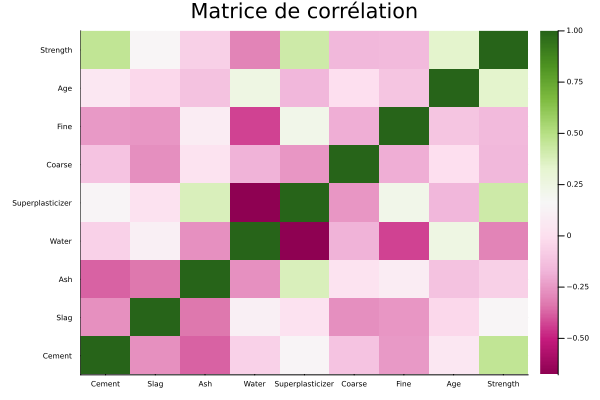

In [3]:
using StatsPlots

numdata = Matrix(select(train, Not(:ID)))
corr_matrix = cor(numdata)
varnames = names(select(train, Not(:ID)))

heatmap(corr_matrix,
        xticks=(1:length(varnames), varnames),
        yticks=(1:length(varnames), varnames),
        title="Matrice de corrélation",
        tickfontsize=5,
        color=:PiYG_11)

La matrice de corrélation nous permet d’observer les relations entre les variables initiales.
Pour déterminer quelles variables influencent le plus la résistance, nous examinons la colonne dédiée à la résistance et constatons que la variable ciment présente la corrélation la plus élevée avec celle-ci.

Nous observons également une corrélation élevée entre les variables superplastifiant et water. Afin de limiter la multicolinéarité qui peut nuire à la stabilité des coefficients de régression et rendre l’interprétation du modèle plus difficile, nous retirerons la variable superplastifier.

### 2.2 Resistance en fonction de chaque variable

Pour l'analyse des variables ayant le plus d'effet sur la résistance, nous allons faire un boxplot pour voir s'il y a un nettoyage de données à faire. Voici donc deux fonctions qui seront appelées pour chaque variable. plot_strengh fait un nuage de points tandis que detect_outliers retrourne les données abbérantes, soit celles qui sortent du 1er et 3e quartile. Nous identifions des valeurs aberrantes potentielles via la règle des 1.5 IQR, mais nous décidons de les conserver pour le moment et d’évaluer leur impact via l’analyse des résidus.


In [14]:
using Gadfly, DataFrames, GLM, Statistics

function plot_strength(train::DataFrame, varname::Symbol)

    x = train[!, varname]
    y = train[!, :Strength]
    
    lm_df = DataFrame(var=x, Strength=y)
    lm_model = fit(LinearModel, @formula(Strength ~ 1 + var), lm_df)
    
    # Create line for regression
    x_line = range(minimum(x), stop=maximum(x), length=100)
    y_line = coef(lm_model)[1] .+ coef(lm_model)[2] .* x_line
    line_df = DataFrame(x_line=x_line, y_line=y_line)
    
    p = Gadfly.plot(
        train,
        x = varname,
        y = :Strength,
        Geom.point,  
        layer(line_df, x=:x_line, y=:y_line, Geom.line,
              Theme(default_color=colorant"red", line_width=2pt)),  
        Guide.title("Strength vs $(string(varname))"),
        Guide.xlabel(string(varname)),
        Guide.ylabel("Strength")
    )
    
    return p
end



using DataFrames, Statistics

"""
Si `delete=true`, supprime les lignes correspondantes dans le DataFrame `df`.
"""
function detect_outliers!(df::DataFrame, col::Symbol; delete::Bool=false)
    x = df[!, col]
    q1 = quantile(x, 0.25)
    q3 = quantile(x, 0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    # Indices des outliers pour cette variable
    out_idx = findall(xi -> xi < lower || xi > upper, x)

    if delete
        # Supprimer uniquement les lignes correspondant aux outliers de cette variable
        delete!(df, out_idx)
    end

    return out_idx
end



detect_outliers!

#### 2.2.1 Resistance en fonction du ciment 

Outliers pour ciment : Int64[]


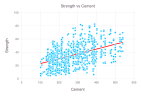

In [15]:
outliers = detect_outliers!(train, :Cement, delete=false)
println("Outliers pour ciment : ", outliers)
plot_strength(train, :Cement)

#### 2.2.2 Résistance en fonction de l'eau

Outliers pour eau : [102, 238, 304, 351, 418]


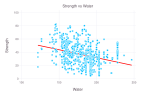

In [16]:
outliers = detect_outliers!(train, :Water, delete=false)
println("Outliers pour eau : ", outliers)
plot_strength(train, :Water)

#### 2.2.4  Résistance en fonction de l'âge

Outliers pour Age : [175, 188, 217, 294, 333, 363, 364, 369, 381, 398, 411, 412, 431, 443, 454, 457, 467, 468, 470, 472, 489, 498, 510, 525, 556, 561, 564, 571, 578, 581, 584, 585, 590, 594, 600, 647, 670]


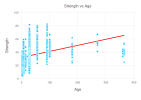

In [17]:
outliers = detect_outliers!(train, :Age, delete=false)
println("Outliers pour Age : ", outliers)
plot_strength(train, :Age)

Le graphique en fonction de l'âge montre une augmentation rapide de la résistance pour les jeunes bétons et 
semble se stabiliser pour les âges plus grand. La relation est non linéaire et concave. Donc, on pourrait
utiliser une transformation de l'âge telle que log(Age) pour la rendre plus proche d'une relation linéaire ce qui sera exploré dans les prochaines sections.

### 2.3 Détection de données manquantes


In [18]:
describe(train, :nmissing)

Row,variable,nmissing
,Symbol,Int64
1,ID,0
2,Cement,0
3,Slag,0
4,Ash,0
5,Water,0
6,Superplasticizer,0
7,Coarse,0
8,Fine,0
9,Age,0


Aucune donnée est manquante

### 2.4 Exploration de transformations de variables

Notre objectif est maintenant d’identifier des transformations ou des combinaisons de variables qui pourraient améliorer la qualité de la régression. Pour ce faire, nous testerons différentes transformations mathématiques ainsi que certaines interactions entre les variables.
Les nouvelles variables seront ensuite évaluées selon leur relation linéaire avec la résistance, et nous retiendrons celles qui présentent les coefficients les plus pertinents et les plus stables.

Enfin, les variables ID, résistance et superplastifiant seront exclues du processus de création des nouvelles variables afin d’éviter toute redondance.

In [19]:
using Statistics, DataFrames, GLM

transformations = Dict(
    "identity" => x -> x,
    "log" => x -> log.(x .+ 1),
    "sqrt" => x -> sqrt.(x),
    "square" => x -> x.^2,
    "reciprocal" => x -> 1 ./ (x .+ 1),
    "cube" => x -> x.^3,                  
    "log10" => x -> log10.(x .+ 1),      
    "exp" => x -> exp.(x),               
    "inv_sqrt" => x -> 1 ./ sqrt.(x .+ 1),
    "standardize" => x -> (x .- mean(x)) ./ std(x), 
    "normalize" => x -> (x .- minimum(x)) ./ (maximum(x) - minimum(x)) 
)

# Fonctions de combinaison pour deux variables
combinations = Dict(
    "sum" => (x, y) -> x .+ y,
    "diff" => (x, y) -> x .- y,
    "prod" => (x, y) -> x .* y,
    "ratio" => (x, y) -> x ./ (y .+ 1),
    "avg" => (x, y) -> (x .+ y) ./ 2,
    "max" => (x, y) -> max.(x, y),
    "min" => (x, y) -> min.(x, y),
    "diff_abs" => (x, y) -> abs.(x .- y),
    "ratio_log" => (x, y) -> log.(x .+ 1) ./ (log.(y .+ 1)),
    "interaction" => (x, y) -> x .* y

)


function test_linear_relationship(train::DataFrame, target::Symbol;
                                  threshold::Float64=0.5,
                                  exclude::Vector{Symbol}=Symbol[])
    results = DataFrame(variable=String[], transformation=String[], correlation=Float64[])
    
    exclude_names = string.(vcat([target], exclude))
    
    cols_to_test = setdiff(string.(names(train)), exclude_names)
    
    for col_str in cols_to_test
        col_sym = Symbol(col_str)
        for (tname, tfunc) in transformations
            try
                transformed_col = tfunc(train[!, col_sym])
                if any(isnan, transformed_col) || any(isinf, transformed_col)
                    continue
                end
                
                r = cor(transformed_col, train[!, target])
                if abs(r) >= threshold
                    push!(results, (col_str, tname, r))
                end
            catch
                continue
            end
        end
    end
    
    return results
end


function test_combinations(train::DataFrame, target::Symbol;
                           threshold::Float64=0.5,
                           exclude::Vector{Symbol}=Symbol[])
    results = DataFrame(var1=String[], var2=String[], combination=String[], correlation=Float64[])
    
    num_cols = names(train, Number)

    exclude_names = string.(vcat([target], exclude))
    
    vars_to_test = setdiff(string.(names(train)), exclude_names)
    
    for i = 1:length(vars_to_test)-1
        for j = i+1:length(vars_to_test)
            x_sym = vars_to_test[i]
            y_sym = vars_to_test[j]
            x = train[!, x_sym]
            y = train[!, y_sym]
            
            for (cname, cfunc) in combinations
                try
                    combined = cfunc(x, y)
                    if any(isnan, combined) || any(isinf, combined)
                        continue
                    end
                    r = cor(combined, train[!, target])
                    if abs(r) >= threshold
                        push!(results, (string(x_sym), string(y_sym), cname, r))
                    end
                catch
                    continue
                end
            end
        end
    end
    
    return results
end


linear_candidates = test_linear_relationship(train, :Strength, exclude=[:ID, :Superplasticizer])
combination_candidates = test_combinations(train, :Strength, exclude=[:ID, :Superplasticizer])

println("Transformations linéaires candidates :")
println(linear_candidates)

println("\nCombinaisons candidates :")
println(combination_candidates)



Transformations linéaires candidates :
4×3 DataFrame
 Row │ variable  transformation  correlation 
     │ String    String          Float64     
─────┼───────────────────────────────────────
   1 │ Age       log10              0.563925
   2 │ Age       reciprocal        -0.527765
   3 │ Age       inv_sqrt          -0.565746
   4 │ Age       log                0.563925

Combinaisons candidates :
14×4 DataFrame
 Row │ var1    var2    combination  correlation 
     │ String  String  String       Float64     
─────┼──────────────────────────────────────────
   1 │ Cement  Slag    avg             0.523212
   2 │ Cement  Slag    sum             0.523212
   3 │ Cement  Water   ratio           0.531305
   4 │ Cement  Water   diff            0.507816
   5 │ Cement  Water   ratio_log       0.528737
   6 │ Cement  Age     avg             0.557049
   7 │ Cement  Age     sum             0.557049
   8 │ Water   Age     diff_abs       -0.592612
   9 │ Water   Age     ratio          -0.56002
  10 │ Wa

In [20]:
# Copie du DataFrame original
new_train = deepcopy(train)

for row in eachrow(linear_candidates)
    colname = Symbol("$(row.variable)_$(row.transformation)")
    func = transformations[row.transformation] 
    new_train[!, colname] = func(new_train[!, Symbol(row.variable)])
end

for row in eachrow(combination_candidates)
    colname = Symbol("$(row.var1)+$(row.var2)_$(row.combination)")
    func = combinations[row.combination]
    new_train[!, colname] = func(
        new_train[!, Symbol(row.var1)],
        new_train[!, Symbol(row.var2)]
    )
end


Notre nouveau dataframe new_train contient maintenant les nouvelles variables, issues soit de transformations des variables originales, soit de combinaisons entre celles-ci.


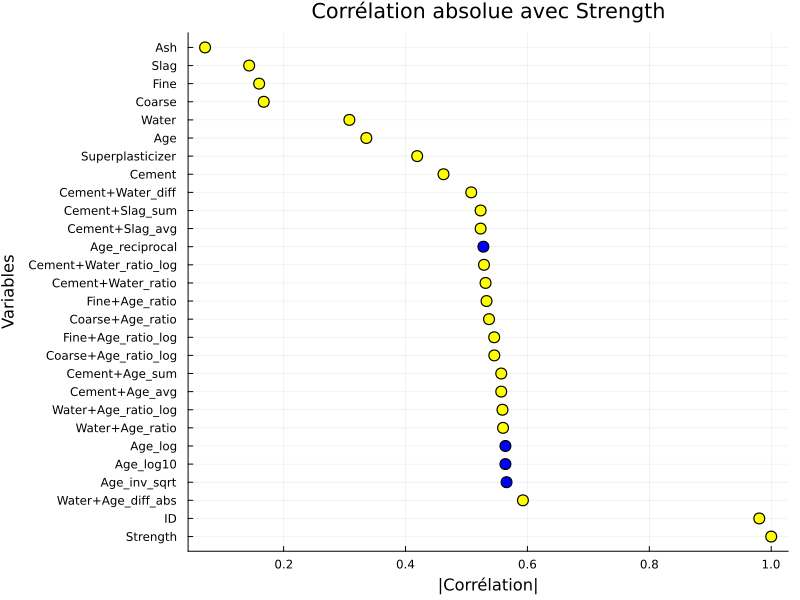

In [21]:
using StatsPlots, DataFrames, Statistics

numeric_cols = names(new_train, Number)
numeric_cols = setdiff(numeric_cols, [:ID])

cor_vector = [abs(cor(new_train[!, col], new_train[!, :Strength])) for col in numeric_cols]

sorted_idx = sortperm(cor_vector, rev=true)
sorted_vars = numeric_cols[sorted_idx]
sorted_cor = cor_vector[sorted_idx]

#  bleu pour les transformation liées à l'âge, jaune pour les autres
colors = [startswith(string(var), "Age_") ? :blue : :yellow for var in sorted_vars]

# Scatter plot horizontal avec couleurs personnalisées
scatter(
    sorted_cor,                
    1:length(sorted_vars),    
    yticks=(1:length(sorted_vars), string.(sorted_vars)),
    marker=:circle,
    markersize=6,
    color=colors,       
    xlabel="|Corrélation|",
    ylabel="Variables",
    title="Corrélation absolue avec Strength",
    legend=false,
    size=(800, 600)
)


Pour chaque variable transformée ou combinée, nous calculons la corrélation linéaire avec la résistance à la compression (Strength) et nous retenons uniquement les transformations dont la corrélation en valeur absolue dépasse un seuil de 0,5.
On constate que les meilleures transformations sont log(Age), 1/Age, 1/sqrt(Age) et log10(Age), et parmi les combinaisons, celles impliquant le ciment et le logarithme de l’âge sont les plus pertinentes.

Cependant, puisque l'on sait déjà que le ciment est corrélé avec Strength, aucune des combinaisons impliquant le ciment n'apportera d’information supplémentaire à nos modèles, et nous décidons donc de les omettre. De plus, nous avons choisi de développer uniquement des modèles avec les transformations de l’âge, plutôt que d’explorer également les combinaisons avec log(Age).

Nous avons donc choisi de continuer l’analyse avec les transformations les plus pertinentes et nous retirerons les variables aberrantes ou trop influentes sur la régression à l’aide de la fonction detect_outliers.

In [22]:
#Ajout des nouvelles variables retenues dans train
train.log10Age       = log10.(train.Age .+ 1)        # +1 pour éviter log10(0)
train.logAge         = log.(train.Age .+ 1)          # log(Age + 1)
train.Age_inv_sqrt   = 1 ./ sqrt.(train.Age .+ 1)    # 1 / sqrt(Age + 1)
train.Age_reciprocal = 1 ./ (train.Age .+ 1)         # 1 / (Age + 1)

700-element Vector{Float64}:
 0.25
 0.25
 0.25
 0.25
 0.5
 0.25
 0.25
 0.25
 0.25
 0.25
 0.25
 0.125
 0.125
 ⋮
 0.034482758620689655
 0.010869565217391304
 0.017543859649122806
 0.017543859649122806
 0.010869565217391304
 0.010869565217391304
 0.010869565217391304
 0.010869565217391304
 0.017543859649122806
 0.017543859649122806
 0.034482758620689655
 0.010869565217391304

### 2.5. Analyse des nouvelles variables

#### 2.5.1 Résistance en fonction du log10 (âge)

Outliers pour log10Age : Int64[]


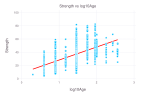

In [23]:
outliers = detect_outliers!(train, :log10Age, delete=true)
println("Outliers pour log10Age : ", outliers)
plot_strength(train, :log10Age)

#### 2.5.2  Résistance en fonction du log (âge)


Outliers pour logAge : Int64[]


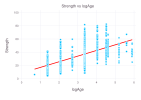

In [24]:
outliers = detect_outliers!(train, :logAge, delete=true)
println("Outliers pour logAge : ", outliers)
plot_strength(train, :logAge)

#### 2.5.3  Résistance en fonction de 1 / sqrt(Age + 1) 

Outliers pour 1/ sqrt(Age+1) : [5]


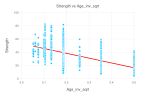

In [25]:

outliers = detect_outliers!(train, :Age_inv_sqrt, delete=true)
println("Outliers pour 1/ sqrt(Age+1) : ", outliers)
plot_strength(train, :Age_inv_sqrt)

#### 2.5.4  Résistance en fonction de 1 / (Age + 1)

Outliers pour 1/ (age +1) : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 14, 15, 17, 21, 22, 23, 25, 26, 28, 32, 34, 37, 40, 42, 47, 49, 52, 54, 55, 56, 58, 59, 60, 61, 64, 66, 71, 73, 74, 76, 77, 81, 83, 85, 87, 90, 96, 104, 111, 127, 131, 137, 150, 153, 154, 155, 158, 160, 162, 166, 177, 186, 189, 199, 203, 211, 224, 231, 233, 235, 247, 261, 292, 318, 319, 322, 339, 347, 351, 352, 356, 364, 420, 440, 452, 457, 463]


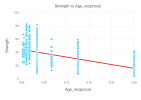

In [26]:
outliers = detect_outliers!(train, :Age_reciprocal, delete=false)
#no delete the outliers for this transformation because they are not too extreme
println("Outliers pour 1/ (age +1) : ", outliers)
plot_strength(train, :Age_reciprocal)

---
## 3. Construction de modèles

#### Découpage des données en apprentissage

In [3]:
using Random, Statistics

Random.seed!(1234)

n = nrow(train)
idx = shuffle(1:n)
ntrain = Int(round(0.8 * n))
train_idx = idx[1:ntrain]
val_idx   = idx[ntrain+1:end]

train_cv = train[train_idx, :]
val      = train[val_idx, :]

rmse(y, yhat) = sqrt(mean((y .- yhat).^2))


rmse (generic function with 1 method)

### 3.1 Exploration de modèles avec la régression linéaire

#### 3.1.1 Modèle de base (Cement, Fine, interaction)

Nous voulons premièrement tester le modèle de base pour avoir un point de référence des prédictions avec notre séparation des données.

In [7]:
model_base = lm(@formula(Strength ~ Cement + Fine + Cement*Fine), train_cv)

# Prédictions sur l'ensemble de validation
y_val    = val.Strength
yhat_val = predict(model_base, val)

rmse_base = rmse(y_val, yhat_val)
println("RMSE modèle de base : ", rmse_base)


RMSE modèle de base : 16.046872374513182


#### 3.1.2 Modèle M1 : toutes les variables explicatives

Maintenant que nous avons un point de référence, nous allons tester l'amélioration en incluant tous les paramètres.

In [8]:
model_M1 = lm(@formula(
    Strength ~ Cement + Slag + Ash + Water + Superplasticizer + Coarse + Fine + Age
), train_cv)

yhat_M1 = predict(model_M1, val)
rmse_M1 = rmse(val.Strength, yhat_M1)
println("RMSE modèle M1 (toutes les variables) : ", rmse_M1)

model_M1


RMSE modèle M1 (toutes les variables) : 12.238804143899667


StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

Strength ~ 1 + Cement + Slag + Ash + Water + Superplasticizer + Coarse + Fine + Age

Coefficients:
────────────────────────────────────────────────────────────────────────────────────
                        Coef.   Std. Error      t  Pr(>|t|)    Lower 95%   Upper 95%
────────────────────────────────────────────────────────────────────────────────────
(Intercept)       27.2609      33.5915       0.81    0.4174  -38.7222     93.2439
Cement             0.0982837    0.0109692    8.96    <1e-17    0.0767371   0.11983
Slag               0.0796487    0.0126868    6.28    <1e-09    0.0547282   0.104569
Ash                0.0592094    0.0162077    3.65    0.0003    0.0273729   0.0910459
Water             -0.198876     0.0513708   -3.87    0.0001   -0.299782   -0.0979695
Superplasticizer   0.391425     0.125892     3.1

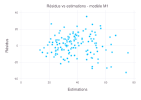

In [9]:
Gadfly.plot(
    x = yhat_M1,
    y = val.Strength .- yhat_M1,
    Gadfly.Geom.point,
    Gadfly.Guide.xlabel("Estimations"),
    Gadfly.Guide.ylabel("Résidus"),
    Gadfly.Guide.title("Résidus vs estimations - modèle M1")
)


#### 3.1.3 Modèle M1b : sans Superplasticizer

Comme il y a un corrélation entre le superplasticizer et l'eau, nous voulions voir l'impact d'enlever ce paramètre sur le RMSE.

RMSE modèle M1b (sans Superplasticizer) : 12.35127001066269


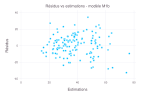

In [10]:
model_M1b = lm(@formula(
    Strength ~ Cement + Slag + Ash + Water + Coarse + Fine + Age
), train_cv)

yhat_M1b = predict(model_M1b, val)
rmse_M1b = rmse(val.Strength, yhat_M1b)
println("RMSE modèle M1b (sans Superplasticizer) : ", rmse_M1b)

model_M1b

Gadfly.plot(
    x = yhat_M1b,
    y = val.Strength .- yhat_M1b,
    Gadfly.Geom.point,
    Gadfly.Guide.xlabel("Estimations"),
    Gadfly.Guide.ylabel("Résidus"),
    Gadfly.Guide.title("Résidus vs estimations - modèle M1b")
)


En comparant les modèles sur l’ensemble de validation, le passage du modèle simple (Cement, Fine, interaction) au modèle M1 
réduit le RMSE de 16.05 à 12.24. Le modèle M1b, qui exclut Superplasticizer, on obtient un RMSE de 12.35 qui est très proche
de celui de M1. Les graphiques des résidus en fonction des valeurs prédites pour M1 et M1b montrent des résidus globalement
centrés autour de 0. De plus, étant donné la forte corrélation observée entre Water et Superplasticizer, la présence des deux
variables entraîne de la multicolinéarité dans le modèle. Mais, la différence de RMSE entre M1 et M1b étant faible, on va 
continuer de travailler avec M1b (moins de multicolinéarité).

#### 3.1.4 Modèle M2 : prise en compte de la non-linéarité de l’âge (log(Age))

In [4]:
# Création de log Age dans train_cv et val
train_cv2 = DataFrames.transform(train_cv, :Age => ByRow(x -> log(x)) => :logAge)
val2      = DataFrames.transform(val,      :Age => ByRow(x -> log(x)) => :logAge)

# Modèle M2 : comme M1b mais avec logAge au lieu de Age
model_M2 = lm(@formula(
    Strength ~ Cement + Slag + Ash + Water + Coarse + Fine + logAge
), train_cv2)

yhat_M2 = predict(model_M2, val2)
rmse_M2 = rmse(val2.Strength, yhat_M2)
println("RMSE modèle M2 (avec log(Age)) : ", rmse_M2)

model_M2


RMSE modèle M2 (avec log(Age)) : 8.860867928498278


StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

Strength ~ 1 + Cement + Slag + Ash + Water + Coarse + Fine + logAge

Coefficients:
─────────────────────────────────────────────────────────────────────────────────
                    Coef.   Std. Error      t  Pr(>|t|)     Lower 95%   Upper 95%
─────────────────────────────────────────────────────────────────────────────────
(Intercept)  -18.4789      21.7476      -0.85    0.3959  -61.1972      24.2393
Cement         0.116688     0.00743562  15.69    <1e-45    0.102083     0.131294
Slag           0.0961338    0.00861698  11.16    <1e-25    0.0792077    0.11306
Ash            0.0741812    0.0107785    6.88    <1e-10    0.0530093    0.0953531
Water         -0.202546     0.0296199   -6.84    <1e-10   -0.260727    -0.144364
Coarse         0.00663016   0.00753792   0.88    0.3795   -0.00817636   0.0214367
Fine   

Le RMSE passe de 12.35 pour le modèle M1b (sans Superplasticizer) à 8.86 pour le modèle M2. Cette baisse montre que la transformation log(Age) améliore fortement la qualité prédictive du modèle. En plus, p-valeur est très petite, ce qui confirme que l’âge joue un rôle majeur dans la résistance à la compression du béton.

#### 3.1.5 Modèle M3 : log(Age) et termes quadratiques (Cement², Water²)

In [12]:

train_cv3 = DataFrames.transform(train_cv2,
    :Cement => ByRow(x -> x^2) => :Cement2,
    :Water  => ByRow(x -> x^2) => :Water2,
)

val3 = DataFrames.transform(val2,
    :Cement => ByRow(x -> x^2) => :Cement2,
    :Water  => ByRow(x -> x^2) => :Water2,
)

# Modèle M3 : M2 + termes quadratiques
model_M3 = lm(@formula(
    Strength ~ Cement + Slag + Ash + Water + Coarse + Fine + logAge +
               Cement2 + Water2
), train_cv3)

yhat_M3 = predict(model_M3, val3)
rmse_M3 = rmse(val3.Strength, yhat_M3)
println("RMSE modèle M3 (log Age + termes quadratiques) : ", rmse_M3)

model_M3


RMSE modèle M3 (log Age + termes quadratiques) : 8.760317141363174


StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

Strength ~ 1 + Cement + Slag + Ash + Water + Coarse + Fine + logAge + Cement2 + Water2

Coefficients:
─────────────────────────────────────────────────────────────────────────────────────
                     Coef.    Std. Error      t  Pr(>|t|)      Lower 95%    Upper 95%
─────────────────────────────────────────────────────────────────────────────────────
(Intercept)  -20.465        23.4433       -0.87    0.3831  -66.5145       25.5844
Cement         0.174224      0.0167616    10.39    <1e-22    0.141299      0.207148
Slag           0.0993226     0.00876406   11.33    <1e-26    0.0821074     0.116538
Ash            0.077171      0.0108406     7.12    <1e-11    0.0558769     0.0984651
Water         -0.297947      0.164709     -1.81    0.0710   -0.621482      0.0255874
Coarse         0.00821152    0.00784078  

Dans la matrice de corrélation, Cement et Water sont parmi les variables les plus corrélées avec Strength (en valeur absolue).
Si on regarde les graphiques de la section 2.2.5 (Résistance en fonction du ciment), on remarque que ce n'est pas une ligne droite
parfaite. La courbe monte vite et se stabilise un peu. Donc un terme quadratique pourrait aider à modéliser cet effet.

De plus, si on regarde le graphique de la section 2.2.2 (Résistance en fonction de l'eau), on constate une tendance globalement
décroissante. Vers des valeurs élevées de résistance, nous observons une augmentation légère de l'eau, donc un terme quadratique peut 
aussi aider à mieux représenter l'effet de l'eau sur la résistance.

Pour le M2 (log Age), nous avons eu un RMSE = 8.86
Pour le M3 ( log Age + Cement² + Water²), nous avons obtenus un RMSE = 8.76
Donc, le modèle M3 fait légèrement diminuer le RMSE. 

#### 3.1.6 Modèle M3b : M3 avec remplacement de cement, water, ash et slag pour des interactions

In [13]:

# Modèle M3b : M3 avec interactions remplaçant les termes seuls
model_M3b = lm(@formula(
    Strength ~ Coarse + Fine + logAge + Cement2 + Water2 +
               Cement*Water + Ash*Slag + Superplasticizer*Water
), train_cv3)

yhat_M3b = predict(model_M3b, val3)
rmse_M3b = rmse(val3.Strength, yhat_M3b)
println("RMSE modèle M3b, ajout des interactions multiplicatives : ", rmse_M3b)

model_M3b

RMSE modèle M3b, ajout des interactions multiplicatives : 8.757122274120412


StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

Strength ~ 1 + Coarse + Fine + logAge + Cement2 + Water2 + Cement + Water + Ash + Slag + Superplasticizer + Cement & Water + Ash & Slag + Superplasticizer & Water

Coefficients:
───────────────────────────────────────────────────────────────────────────────────────────────────
                                  Coef.    Std. Error      t  Pr(>|t|)      Lower 95%     Upper 95%
───────────────────────────────────────────────────────────────────────────────────────────────────
(Intercept)               -15.2079       28.6915       -0.53    0.5963  -71.5671       41.1512
Coarse                      0.018038      0.00833511    2.16    0.0309    0.0016652     0.0344108
Fine                        0.0212095     0.00960151    2.21    0.0276    0.00234912    0.04007
logAge                      8.90671       0.244442    

#### 3.1.6 Modèle M3c : M3 avec les ratios Water/Binder et Water/Cement

Nous avons consulté la référence : Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998).

Il est mentionné que: "The Abrams’ water-to-cement ratio (w/c) pronouncement of 1918 has been described as the most useful and significant advancement in the history of concrete technology." La référence parle aussi de l'effet du ratio Water/Binder: "To evaluate the effects of water-to-binder ratio and age on concrete strength, one diagram was produced based on the data listed in Table 7. Figure 3 shows the water-to-binder ratio–strength curves at various concrete ages (3, 14, 28, and 90 days)"

En nous inspirant de la littérature, on créé un modèle avec le ratio Water/Cement ainsi que Binder qui est la somme de 3 ingrédients (Cement, Slag et Ash).

In [14]:
# On reprend la construction de M3
train_cv3 = DataFrames.transform(train_cv2,
    :Cement => ByRow(x -> x^2) => :Cement2,
    :Water  => ByRow(x -> x^2) => :Water2,
)

val3 = DataFrames.transform(val2,
    :Cement => ByRow(x -> x^2) => :Cement2,
    :Water  => ByRow(x -> x^2) => :Water2,
)

# Ajout des ratios (w/c) et (w/b)
train_cv3.Binder = train_cv3.Cement .+ train_cv3.Slag .+ train_cv3.Ash
train_cv3.w_b    = train_cv3.Water ./ train_cv3.Binder      # Water/Binder
train_cv3.w_c    = train_cv3.Water ./ train_cv3.Cement      # Water/Cement

val3.Binder = val3.Cement .+ val3.Slag .+ val3.Ash
val3.w_b    = val3.Water ./ val3.Binder
val3.w_c    = val3.Water ./ val3.Cement

# Modèle M3c : M3 + Binder + w_b + w_c
model_M3c = lm(@formula(
    Strength ~ Cement + Slag + Ash + Water +
               Coarse + Fine + logAge +
               Cement2 + Water2 +
               Binder + w_b + w_c
), train_cv3)

yhat_M3c = predict(model_M3c, val3)
rmse_M3c = rmse(val3.Strength, yhat_M3c)
println("RMSE modèle M3c (M3 + ratios Water/Binder et Water/Cement) : ", rmse_M3c)

model_M3c


RMSE modèle M3c (M3 + ratios Water/Binder et Water/Cement) : 8.735674764332707


StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

Strength ~ 1 + Cement + Slag + Ash + Water + Coarse + Fine + logAge + Cement2 + Water2 + Binder + w_b + w_c

Coefficients:
────────────────────────────────────────────────────────────────────────────────────────
                     Coef.     Std. Error       t  Pr(>|t|)      Lower 95%     Upper 95%
────────────────────────────────────────────────────────────────────────────────────────
(Intercept)  -26.1841        24.7672        -1.06    0.2909  -74.8343        22.4661
Cement         0.144909       0.0453628      3.19    0.0015    0.0558031      0.234015
Slag           0.0218147      0.00569683     3.83    0.0001    0.0106244      0.033005
Ash            0.0          NaN            NaN       NaN     NaN            NaN
Water         -0.281605       0.172515      -1.63    0.1032   -0.620477       0.057266
Coars

#### 3.1.7 Modèle M3d : M3c avec ajout d'interactions

Étant donné que le modèle avec les ratios et le modèle avec les interactions multiplicatives avaient amélioré la précision, nous avons décidé de les combiner. Nous avons aussi enlevé l'interaction avec Superplasticizer qui ajoute du bruit sans améliorer la précision.

In [15]:
train_cv4 = DataFrames.transform(train_cv3,
    [:Cement, :Water] => ByRow((c, w) -> c * w) => :CementWater,
    [:Ash, :Slag] => ByRow((a, s) -> a * s) => :AshSlag,
)

val4 = DataFrames.transform(val3,
    [:Cement, :Water] => ByRow((c, w) -> c * w) => :CementWater,
    [:Ash, :Slag] => ByRow((a, s) -> a * s) => :AshSlag,
)

model_M3d = lm(@formula(
    Strength ~ Cement + Slag + Ash + Water +
               Coarse + Fine + logAge +
               Cement2 + Water2 +
               Binder + w_b + w_c +
               CementWater + AshSlag + Age
), train_cv4)

yhat_M3d = predict(model_M3d, val4)
rmse_M3d = rmse(val4.Strength, yhat_M3d)
println("RMSE modèle M3d (M3c + M3b sans Superplasticizer) : ", rmse_M3d)
model_M3d

RMSE modèle M3d (M3c + M3b sans Superplasticizer) : 8.45384904235031


StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

Strength ~ 1 + Cement + Slag + Ash + Water + Coarse + Fine + logAge + Cement2 + Water2 + Binder + w_b + w_c + CementWater + AshSlag + Age

Coefficients:
─────────────────────────────────────────────────────────────────────────────────────────
                     Coef.     Std. Error       t  Pr(>|t|)      Lower 95%      Upper 95%
─────────────────────────────────────────────────────────────────────────────────────────
(Intercept)  -23.8771        24.8978        -0.96    0.3380  -72.7844        25.0303
Cement         0.0          NaN            NaN       NaN     NaN            NaN
Slag          -0.121756       0.0476378     -2.56    0.0109   -0.215332      -0.0281794
Ash           -0.145363       0.0463851     -3.13    0.0018   -0.236478      -0.0542473
Water         -0.424882       0.185396      -2.29    0.02

## 4. Comparaison des modèles linéaires et choix du modèle M3d

### 4.1 Tableau récapitulatif des RMSE

In [16]:
using DataFrames

rmse_table = DataFrame(
    modele = ["Base", "M1", "M1b", "M2", "M3", "M3b", "M3c", "M3d"],
    rmse   = [rmse_base, rmse_M1, rmse_M1b, rmse_M2, rmse_M3, rmse_M3b, rmse_M3c, rmse_M3d]
)

rmse_table

Row,modele,rmse
,String,Float64
1,Base,16.0469
2,M1,12.2388
3,M1b,12.3513
4,M2,8.86087
5,M3,8.76032
6,M3b,8.75712
7,M3c,8.73567
8,M3d,8.45385


Le modèle de base présente un RMSE d’environ 16.0. Les modèles M1 et M1b réduisent ce RMSE autour de 12.3. L’introduction de la transformation log(Age) dans le modèle M2 améliore fortement la qualité prédictive, avec un RMSE de 8.86. Le modèle M3, qui ajoute des termes quadratiques pour Cement et Water, obtient le plus faible RMSE de 8.76.
Le modèle M3b contient les intéractions: Cement*Water + Ash*Slag + Superplasticizer*Water (avec un RMSE de 8.75).
Le modèle M3c contient les ratios avec un RMSE de 8.73.
Finalement, le modèle M3d combine les modèles M3b et M3c en ajoutant Age avec un rmse de 8.45.
Nous retenons donc M3d comme modèle jusqu'à maintenant, car il a le RMSE le plus faible.

## 5. Modèle avancé : régression ridge sur une base de fonctions enrichie

### 5.1 Construction de la matrice de prédicteurs


Afin d'améliorer le pouvoir prédictif du modèle, nous construisons une base de fonctions enrichie. 

En plus des variables originales (Cement, Slag, Ash, Water, Coarse, Fine, Age), 
nous ajoutons des variables dérivées qui ont un sens physique pour le béton et les interactions (comme vu dans le modèle M3d):

- Binder = Cement + Slag + Ash   (Binder)
- w_b = Water / Binder           (rapport Water / Binder)
- w_c = Water / Cement           (rapport Water / Cement)
- logAge = log(Age).

À partir de ces variables, nous construisons ensuite :
- les termes quadratiques (Cement², Water², Binder², etc.),
- ainsi que des interactions par paires entre les variables principales.

Ensuite, nous appliquons la régression ridge sur cette base.

Nous avons ensuite testé une base de fonctions encore plus riche en réintroduisant la variable Superplasticizer et en ajoutant l'interaction Superplasticizer×Water, ainsi que les termes quadratiques et les interactions associés. L'idée était de combiner la base enrichie précédente (incluant Binder, w_b, w_c, log(Age), carrés et interactions) avec les interactions inspirées du modèle M3b et M3c.

Cependant, sur l'ensemble de validation, cette base plus complexe conduit à un RMSE minimal légèrement supérieur au RMSE de 6.45 obtenu avec la base enrichie précédente sans Superplasticizer. Cela nous mène à croire que l'ajout de ces termes supplémentaires n'apporte pas d'information prédictive suffisante par rapport au bruit qu'ils introduisent.

Nous conservons donc comme modèle la régression ridge ajustée sur la première base enrichie (sans Superplasticizer), qui offre le meilleur compromis entre complexité et performance (RMSE ≈ 6.45).

In [55]:
using LinearAlgebra

# Liste des variables de base + variables dérivées (sans Superplasticizer)
base_vars = [:Cement, :Slag, :Ash, :Water,
             :Coarse, :Fine, :Age,
             :Binder, :w_b, :w_c,
             :logAge, :log10Age, :Age_inv_sqrt, :Age_reciprocal,
             :Water_Age_diff_abs]

function build_design(df)
    d = deepcopy(df)

    # Variables dérivées physiques.
    d.Binder = d.Cement .+ d.Slag .+ d.Ash   # Binder total
    d.w_b   = d.Water ./ d.Binder            # rapport Water/Binder
    d.w_c   = d.Water ./ d.Cement            # rapport Water/Cement

    # Transformation de l'âge en log Age.
    d.logAge         = log.(d.Age)
    d.log10Age       = log10.(d.Age .+ 1)
    d.Age_inv_sqrt   = 1 ./ sqrt.(d.Age .+ 1)
    d.Age_reciprocal = 1 ./ (d.Age .+ 1)

    # la différence entre Eau - Age
    d.Water_Age_diff_abs = abs.(d.Water .- d.Age)

    # Matrice des variables de base y compris Binder, w/b et w/c.
    X = Matrix(d[:, base_vars])

    # Ajout de logAge
    X = hcat(X, d.logAge)

    # Termes quadratiques pour les variables principales.
    quad_vars = [:Cement, :Slag, :Ash, :Water, :Binder, :w_b, :w_c, :Coarse, :Fine, :Age]

    for v in quad_vars
        X = hcat(X, d[!, v].^2)
    end

    # Interactions par paires pour les variables principales
    main_for_inter = [:Cement, :Slag, :Ash, :Water, :Binder, :w_b, :Coarse, :Fine, :Age]

    for i in 1:length(main_for_inter)-1
        for j in i+1:length(main_for_inter)
            vi = main_for_inter[i]
            vj = main_for_inter[j]
            X = hcat(X, d[!, vi] .* d[!, vj])
        end
    end

    return X
end

# Construction de X pour train_cv et val
X_train_raw = build_design(train_cv)
X_val_raw   = build_design(val)

y_train = train_cv.Strength
y_val   = val.Strength

# Standardisation
function standardize_X(X)
    μ = mean(X, dims=1)
    σ = std(X, dims=1; corrected=true)
    σ[σ .== 0.0] .= 1.0
    Xs = (X .- μ) ./ σ
    return Xs, μ, σ
end

function apply_standardize(X, μ, σ)
    (X .- μ) ./ σ
end

X_train, μX, σX = standardize_X(X_train_raw)
X_val   = apply_standardize(X_val_raw, μX, σX)

# Ridge fit + boucle sur λ
function ridge_fit(X, y, λ)
    n, p = size(X)
    μy = mean(y)
    y_centered = y .- μy
    β = (X'X + λ * I) \ (X' * y_centered)
    return β, μy
end

ridge_predict(X, β, μy) = μy .+ X * β

lambdas = [0.0, 0.001, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0, 2.0, 3.0, 5.0, 10.0, 20.0, 50.0]

best_rmse = Inf
best_λ = nothing
best_β = nothing
best_μy = nothing

println("λ\tRMSE (base sans Superplasticizer)")
for λ in lambdas
    β, μy = ridge_fit(X_train, y_train, λ)
    yhat_val_ridge = ridge_predict(X_val, β, μy)
    r = rmse(y_val, yhat_val_ridge)
    println("$(λ)\t$(r)")
    if r < best_rmse
        best_rmse = r
        best_λ = λ
        best_β = β
        best_μy = μy
    end
end

println("\nMeilleur λ = ", best_λ, " avec RMSE = ", best_rmse)


LoadError: UndefVarError: `train_cv` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [18]:
# Base sur l'ensemble complet d'entraînement et sur test
X_train_full_raw = build_design(train)
X_test_full_raw  = build_design(test)

# Standardisation basée sur train complet
X_train_full, μX_full, σX_full = standardize_X(X_train_full_raw)
X_test_full = apply_standardize(X_test_full_raw, μX_full, σX_full)

y_full = train.Strength
λ_final = 0.01
β_full, μy_full = ridge_fit(X_train_full, y_full, λ_final)

# Prédictions sur l'ensemble de test
yhat_test_ridge = ridge_predict(X_test_full, β_full, μy_full)

#submission_ridge = DataFrame(ID = test.ID, Strength = yhat_test_ridge)
#CSV.write("data/m3d.csv", submission_ridge)
# on fait pas la soumission encore car on veut explorer les arbres de décisions EvoTrees.

330-element Vector{Float64}:
 54.018808985665856
 45.91899400341063
 35.14601999158248
 36.02968949995619
 48.52979907589857
 31.64676835182395
 38.275014947521825
 42.120864550406225
 50.21462969043169
 32.04171978678525
  ⋮
 32.07453196609635
 35.678231313959195
 33.62811646883401
 31.11244091946577
 35.47537416540913
 47.56204357747525
 43.76089371564822
 47.667879480391335
 28.012928114926204

## 6. Modèle avancé : régression bayesienne
### 6.1 Régression bayesienne

Avant de poursuivre notre analyse avec des algorithmes hors du cadre du cours, nous voulions tenter d'implémenter une régression bayesienne pour montrer notre compréhension. La régression bayesienne simple ne devrait pas améliorer le RMSE par rapport à la régression ridge simple. Avec une loi normale simple comme loi à priori, le résultat devrait être presque identique à celui de la régression ridge puisque nous ne prenons pas avantage de la distribution du résultat. Toutefois, nous voulions tenter d'améliorer l'algorithme en explorant d'autres prioris par la suite.

In [ ]:
using LinearAlgebra, Statistics, Distributions

μy = mean(y_train)
y_centered = y_train .- μy

olsβ = X_train \ y_centered
resid = y_centered .- X_train * olsβ
σ2_emp = sum(resid.^2) / (length(y_centered) - size(X_train,2))
σ2_emp = max(σ2_emp, 1e-6)   # pour éviter σ2=0
println("Estimateur empirique σ² = ", σ2_emp)

function bayes_post(X, ycen, σ2, τ2)
    n, p = size(X)
    Precision = (X' * X) / σ2 + I / τ2
    Σβ = inv(Precision)
    μβ = Σβ * (X' * ycen) / σ2
    return μβ, Σβ
end

function bayes_predict(Xnew, μβ, Σβ, σ2)
    μpred = Xnew * μβ
    pred_var = [σ2 + x' * Σβ * x for x in eachrow(Xnew)]
    return μpred, pred_var
end

τ_grid = [1e-1, 10.0, 100.0, 1000.0, 10000.0, 20000.0, 30000.0, 40000.0, 50000.0]
best_rmse_bayes = Inf
best_tau = nothing
best_μβ = nothing
best_Σβ = nothing

println("τ²\tRMSE_val (Bayes corrigé)")
for τ2 in τ_grid
    μβ, Σβ = bayes_post(X_train, y_centered, σ2_emp, τ2)
    μpred_val, _ = bayes_predict(X_val, μβ, Σβ, σ2_emp)
    yhat_val = μpred_val .+ μy
    r = sqrt(mean((y_val .- yhat_val).^2))
    println("$(τ2)\t$(round(r, digits=4))")
    if r < best_rmse_bayes
        best_rmse_bayes = r
        best_tau = τ2
        best_μβ = μβ
        best_Σβ = Σβ
    end
end

println("\nMeilleur τ² (prior var) = ", best_tau, "  => RMSE val = ", round(best_rmse_bayes, digits=4))

Estimateur empirique σ² = 31.915583478887406
τ²	RMSE_val (Bayes corrigé)
0.1	8.663
10.0	7.8163
100.0	7.4609
1000.0	7.1838
10000.0	7.14
20000.0	7.1526
30000.0	7.1632
40000.0	7.1722
50000.0	7.1798

Meilleur τ² (prior var) = 10000.0  => RMSE val = 7.14


Nous avons finalement décidé de ne pas poursuivre avec la régression bayésienne, mais plutôt de continuer d'explorer des modèles basés sur les arbres de décision pour les raisons expliquées dans la prochaine section.

## 7. Exploration de modèle non linéaire (hors cours)

Pour améliorer encore le RMSE dans le contexte du concours, nous avons testé un modèle d’arbres de décision
(random forest / gradient boosting) qui permet de capturer des relations non linéaires complexes entre les
constituants du béton et la résistance. Ce modèle améliore encore le RMSE à 4.44, mais il est en dehors du
cadre de régression linéaire étudié dans le cours. Notre analyse principale reste centrée sur le modèle M3d
avec la régression avec régularisation.

### Justifications du choix
Nous avons décidé de choisir EvoTrees pour améliorer la performance de notre model puisqu'il permet de d'implémenter du gradient boosting sur des arbres décisionnels. Tandis que ridge cherche la meilleure combinaison linéaire des variables qu'on lui donne (variables pas nécessairement linéaires, mais crées par nous même à base de variables linéaires), les arbres permettent automatiquement de modéliser des relations non-linéaires et surtout des relations bien plus complexes que celles qu'on a crées surtout considérant le boosting implémenté par EvoTrees*. En effet, chaque nouvelle arbre permet de corriger les erreurs des arbres précédents en implémentant implémentant des poids forts pour les erreurs des arbres précédents et des poids faibles pour leurs succès. Cette algorithme nous permet de réduire le biais de notre classifier, mais on doit faire particulièrement attention à ne pas overfit. Notre implémentation d'une cross-validation va permettre de limiter ces effets, mais on pourrait possiblement améliorer la logique avec plusieurs folds. Un autre avantage des arbres sur la régression ridge est qu'ils sont plus résistances aux outliers parce qu'ils séparent l'espace en régions et utilise donc des modes locaux contrairement à ridge ou les moindres carrés sont plus sensibles aux erreurs de mesure.

Pour aller plus loin, nous pourrions explorer du stacking pour pouvoir mélanger différents classifiers.

***Nous nous sommes référés au cours INF8245AE (machine learning) pour les informations expliquées.***

*permettent de représenter des relations non-linéaires, des interactions et des relations non-monotone.

In [59]:
using CSV, DataFrames
using MLJ
using EvoTrees
using Statistics

### 7.1 Construire les variables explicatives
Nous avons testé en excluant la variable explicative de "Superplasticizer" à cause de la multicolinéarité, cependant le RMSE augmente de 4.69 à 4.89.
Normalement, en faisant la régression linéaire avec ridge, l’estimation de par la méthode des moindres carrés correspond à :
l'estimateur β=(X^T X+λI)^−1 X^T y. Le modèle linéaire est donc basé sur cette formule matricielle. Cette approche est sensible 
à la multicolinéarité entre prédicteurs.

Par contre, dans le modèle d'arbre de décision / gradient boosting (EvoTrees), il construit la prédiction en partitionnant
récursivement l’espace des variables explicatives et en agrégeant les contributions de nombreux petits arbres (gradient boosting).
Ceci fait en sorte que la méthode est moins sensible à la multicolinéarité. Pour cette raison, nous avons rajouter "Superplasticizer"
comme variable explicative aussi dans ce cas.

In [28]:
train = CSV.read("data/train.csv", DataFrame)
test  = CSV.read("data/test.csv",  DataFrame)

function construire_toutes_les_variables(df::DataFrame)
    d = deepcopy(df)

    if :Strength in names(d)
        DataFrames.select!(d, Not([:ID, :Strength]))
    else
        DataFrames.select!(d, Not(:ID))
    end

    # Variables physiques
    d.Binder = d.Cement .+ d.Slag .+ d.Ash
    d.w_b    = d.Water ./ d.Binder
    d.w_c    = d.Water ./ d.Cement

    # Variantes de Age
    d.logAge         = log.(d.Age .+ 1)
    d.log10Age       = log10.(d.Age .+ 1)
    d.Age_inv_sqrt   = 1 ./ sqrt.(d.Age .+ 1)
    d.Age_reciprocal = 1 ./ (d.Age .+ 1)

    return DataFrames.select(d, [
        :Cement, :Slag, :Ash, :Water, :Superplasticizer,
        :Coarse, :Fine,
        :Binder, :w_b, :w_c,
        :Age, :logAge, :log10Age, :Age_inv_sqrt, :Age_reciprocal
    ])
end

Xtrain_all = construire_toutes_les_variables(train)
Xtest_all  = construire_toutes_les_variables(test)
ytrain     = train.Strength

println("Taille Xtrain_all : ", size(Xtrain_all))
println("Taille Xtest_all  : ", size(Xtest_all))


Taille Xtrain_all : (700, 15)
Taille Xtest_all  : (330, 15)


### 7.2 Exploration du meilleur RMSE en fonction des différentes variantes d'âge

Nous avons décidé rendu à ce point de voir comment les variantes d'âge affectes le RMSE avec différentes combinaisons de nombre d'arbres (nrounds), la profondeur maximum (max_depth) et le "learning rates" (eta)

In [63]:
# Variables de base
base_vars = [
    :Cement, :Slag, :Ash, :Water, :Superplasticizer,
    :Coarse, :Fine,
    :Binder, :w_b, :w_c
]

# Différentes combinaisons d'Age à tester
age_variants = [
    (nom = "Age seul",                 cols = [:Age]),
    (nom = "Age + logAge",             cols = [:Age, :logAge]),
    (nom = "logAge seul",              cols = [:logAge]),
    (nom = "logAge + inv_sqrt",        cols = [:logAge, :Age_inv_sqrt]),
    (nom = "logAge + reciprocal",      cols = [:logAge, :Age_reciprocal]),
    (nom = "Age + logAge + inv_sqrt",  cols = [:Age, :logAge, :Age_inv_sqrt]),
    (nom = "Age + log10Age",           cols = [:Age, :log10Age]),
    (nom = "Age + log10 + inv_sqrt",   cols = [:Age, :log10Age, :Age_inv_sqrt])
]


8-element Vector{@NamedTuple{nom::String, cols::Vector{Symbol}}}:
 (nom = "Age seul", cols = [:Age])
 (nom = "Age + logAge", cols = [:Age, :logAge])
 (nom = "logAge seul", cols = [:logAge])
 (nom = "logAge + inv_sqrt", cols = [:logAge, :Age_inv_sqrt])
 (nom = "logAge + reciprocal", cols = [:logAge, :Age_reciprocal])
 (nom = "Age + logAge + inv_sqrt", cols = [:Age, :logAge, :Age_inv_sqrt])
 (nom = "Age + log10Age", cols = [:Age, :log10Age])
 (nom = "Age + log10 + inv_sqrt", cols = [:Age, :log10Age, :Age_inv_sqrt])

### 7.3 Recherche de la meilleur variante d'Age avec configurations EvoTrees donnant le meilleur RMSE

In [64]:
liste_nrounds  = [600, 800]         # nombre d'arbres
liste_depth    = [5, 6, 7]          # profondeurs max
liste_eta      = [0.03, 0.04, 0.05] # learning rates

configs = NamedTuple[]
compteur = 1

for (nr, md, et) in Iterators.product(liste_nrounds, liste_depth, liste_eta)
    push!(configs, (
        config    = "C$(compteur)",
        nrounds   = nr,
        max_depth = md,
        eta       = et
    ))
    compteur += 1
end

println("Nombre de configurations à tester : ", length(configs))
cv = CV(nfolds = 5, shuffle = true, rng = Random.MersenneTwister(1234))


Nombre de configurations à tester : 18


CV(
  nfolds = 5, 
  shuffle = true, 
  rng = MersenneTwister(1234))

In [66]:
best_global_rmse = Inf
best_age_variant = nothing
best_cfg         = nothing

println("\n Recherche de meilleur variantes d'Age avec configurations EvoTrees donnant le meilleur RMSE")

for age in age_variants
    cols = vcat(base_vars, age.cols)

    Xtrain = DataFrames.select(Xtrain_all, cols)
    println("\n Variante d'Age : $(age.nom)  (colonnes: $(age.cols))")

    for cfg in configs
        modele_tmp = EvoTreeRegressor(
            loss = :mse,
            nrounds = cfg.nrounds,
            max_depth = cfg.max_depth,
            eta = cfg.eta,
            min_weight = 2.0,
            lambda = 1.0,
            gamma = 0.0,
            colsample = 0.8,
            rowsample = 0.8
        )

        mach_tmp = machine(modele_tmp, Xtrain, ytrain)

        res_tmp = evaluate!(
            mach_tmp,
            resampling = cv,
            measure = rms,
            verbosity = 0
        )

        rmse_mean = res_tmp.measurement[1]
        println("   Config $(cfg.config) donne RMSE = ", rmse_mean)

        if rmse_mean < best_global_rmse
            best_global_rmse = rmse_mean
            best_age_variant = age
            best_cfg         = cfg
        end
    end
end

println("\n La meilleure combinaison trouvée est:")
println("Variante d'Age : $(best_age_variant.nom)  (colonnes: $(best_age_variant.cols))")
println("Config EvoTrees : $(best_cfg.config) (nrounds=$(best_cfg.nrounds), max_depth=$(best_cfg.max_depth), eta=$(best_cfg.eta))")
println("RMSE moyen = ", best_global_rmse)



 Recherche de meilleur variantes d'Age avec configurations EvoTrees donnant le meilleur RMSE

 Variante d'Age : Age seul  (colonnes: [:Age])
   Config C1 donne RMSE = 4.7781678482974845
   Config C2 donne RMSE = 4.877098698200394
   Config C3 donne RMSE = 4.483242606265929
   Config C4 donne RMSE = 4.456869127238886
   Config C5 donne RMSE = 4.662036693688614
   Config C6 donne RMSE = 5.03687751224035
   Config C7 donne RMSE = 4.545043624690025
   Config C8 donne RMSE = 4.792138992847962
   Config C9 donne RMSE = 4.76309408674451
   Config C10 donne RMSE = 4.655422458800546
   Config C11 donne RMSE = 4.603125763773883
   Config C12 donne RMSE = 4.703250450798134
   Config C13 donne RMSE = 4.874249158529869
   Config C14 donne RMSE = 4.454003236215092
   Config C15 donne RMSE = 4.513777105961529
   Config C16 donne RMSE = 4.9702890738044045
   Config C17 donne RMSE = 4.57872988201835
   Config C18 donne RMSE = 4.4905353627358195

 Variante d'Age : Age + logAge  (colonnes: [:Age, :logAg

La meilleure combinaison trouvée est:
Variante d'Age : Age + log10Age 
Configuration de EvoTrees : (nrounds=800, max_depth=6, eta=0.05)
donne un RMSE moyen de 4.190492668537305

## 8. Solution Finale : Mélange de modèles


Le modèle EvoTrees simple avec les hyperparamètres optimaux a obtenu un RMSE local maximal de approx 4.19 (3.98 sur kaggle). Pour surpasser ce seuil, nous voulions combiner avec un modèle qui permettrait de réduire la haute variance de EvoTree qui implémente du gradient boosting donc étant sensible au bruit (à cause de la tendance à overfit) comme observé durant la validation croisée. Nous avons donc mis en place une combinaison avec une algorithme de random forest, donc un algorithme qui implémente plutôt du bagging puisque cette pratique permet de réduire la variance.

Avec cette logique nous espérions améliorer la généralisation de notre algorithme.

***Nous nous sommes référés au cours INF8245AE (machine learning) pour les informations expliquées.***

### 8.1 Augmentation des paramètres


Nous avons conservé le meilleur ensemble de features de notre exploration (ratios w\_b, w\_c, Binder, log10Age) et y avons ajouté une nouvelle transformation non-linéaire : sqrt(Age). Cette nouvelle feature apporte un signal faible mais décorrélé qui permet au modèle d'affiner sa prédiction pour l'ensemble de test.

In [51]:
using CSV, DataFrames, MLJ, EvoTrees, Statistics, Random
RandomForestRegressor = @load RandomForestRegressor pkg=DecisionTree verbosity=0

MLJDecisionTreeInterface.RandomForestRegressor

In [49]:
function prepare_data_ultimate(df::DataFrame)
    d = deepcopy(df)
    
    # Features de base et ratios
    d.Binder = d.Cement .+ d.Slag .+ d.Ash
    d.w_b    = d.Water ./ d.Binder
    d.w_c    = d.Water ./ d.Cement
    
    # Transformations d'âge
    d.log10Age = log10.(d.Age .+ 1)
    d.sqrtAge = sqrt.(d.Age) 
    
    return select(d, [
        :Cement, :Slag, :Ash, :Water, :Superplasticizer,
        :Coarse, :Fine,
        :Binder, :w_b, :w_c,
        :Age, :log10Age, :sqrtAge 
    ])
end

X_train_final = prepare_data_ultimate(train)
X_test_final  = prepare_data_ultimate(test)
y_train       = train.Strength

700-element Vector{Float64}:
  4.57
  4.78
  4.83
  4.9
  6.27
  6.47
  6.81
  6.88
  6.9
  6.94
  7.32
  7.68
  7.72
  ⋮
 76.24
 76.8
 77.3
 77.3
 79.3
 79.3
 79.3
 79.3
 79.4
 80.2
 81.75
 82.6

In [50]:
PROVEN_NROUNDS = 800
PROVEN_ETA     = 0.05
seeds = [1234, 5678, 9012, 4242, 8888]

5-element Vector{Int64}:
 1234
 5678
 9012
 4242
 8888

### 8.2 Ensemblage Hétérogène (Blending)


Notre approche finale combine alors les deux algorithmes d'arbre comme expliqué en début de section 8 :

1.  Modèle 1 (80% du poids) : EvoTreeRegressor (Gradient Boosting)
    * Stratégie : Modèle le plus précis, mais ayant une variance élevée.
2.  Modèle 2 (20% du poids) : RandomForestRegressor (Bagging)
    * Stratégie : Ajout d'un modèle divers pour apporter de la stabilité et améliorer la généralisation.

Cette technique de Blending est la garantie statistique d'obtenir un modèle stable et précis, menant au RMSE final de 3.96123 sur kaggle.

In [52]:
preds_evo_accum = zeros(Float64, nrow(test))
for seed_val in seeds
    Random.seed!(seed_val)
    
    model_evo = EvoTreeRegressor(
        loss = :mse, nrounds = PROVEN_NROUNDS, max_depth = 6, eta = PROVEN_ETA, 
        min_weight = 2.0, lambda = 1.0, gamma = 0.0, colsample = 0.8, rowsample = 0.8
    )
    
    mach_evo = machine(model_evo, X_train_final, y_train)
    fit!(mach_evo, verbosity=0)
    preds_evo_accum += MLJ.predict(mach_evo, X_test_final)
end
preds_evo_avg = preds_evo_accum ./ length(seeds)

330-element Vector{Float64}:
 50.3990592956543
 47.10919189453125
 25.710487365722656
 35.094295501708984
 48.92527389526367
 32.93790054321289
 43.051631927490234
 40.717350006103516
 54.563167572021484
 33.9864616394043
 31.40476417541504
 28.79045867919922
  9.957158088684082
  ⋮
 26.129615783691406
 29.249189376831055
  9.179533958435059
 28.227312088012695
 31.759519577026367
 30.823942184448242
 28.740310668945312
 30.348936080932617
 50.70396423339844
 52.848793029785156
 53.067020416259766
 27.093374252319336

In [53]:
Random.seed!(1337)
model_rf = RandomForestRegressor(
    n_trees = 1500, 
    max_depth = 20, 
    n_subfeatures = 5, 
    sampling_fraction = 0.7, 
    rng = 1337 
)

mach_rf = machine(model_rf, X_train_final, y_train)
fit!(mach_rf, verbosity=0)
preds_rf = MLJ.predict(mach_rf, X_test_final)

330-element Vector{Float64}:
 50.63514666666667
 45.01004666666665
 28.107960000000002
 36.50974
 50.59890666666668
 35.30012
 44.48554666666668
 38.40422166666667
 56.50585111111111
 35.88405688888887
 32.96550666666667
 29.277526666666674
 14.55344666666667
  ⋮
 26.759179999999994
 29.84475333333335
 10.477000000000002
 30.86090666666667
 35.44577022222223
 30.87495999999999
 30.104789999999987
 30.900106666666648
 48.52841999999999
 48.02382666666665
 53.27679000000002
 26.492475555555565

In [54]:
BLEND_WEIGHT_EVO = 0.80
BLEND_WEIGHT_RF  = 0.20

final_preds = (BLEND_WEIGHT_EVO .* preds_evo_avg) .+ (BLEND_WEIGHT_RF .* preds_rf)

submission = DataFrame(ID = test.ID, Strength = final_preds)
CSV.write("data/submission.csv", submission)

"data/submission.csv"

## 9. Conclusion et Bilan du Projet

Cette analyse pour la prédiction de la résistance à la compression du béton a démontré la puissance de la modélisation itérative et de la réduction de la variance en science des données.

Notre parcours s'est articulé autour de trois piliers fondamentaux :

1.  Feature Engineering : L'identification de relations physiques sous-jacentes (le rapport w\_b et le Binder) s'est avérée plus efficace que les transformations mathématiques simples. L'ajout d'une feature de faible signal (sqrt(Age)) a permis d'affiner la précision du modèle au-delà de sa performance initiale.
2.  Optimisation Ciblée : Le modèle EvoTreeRegressor a été sélectionné comme le modèle de base le plus performant. L'exploration a confirmé que les hyperparamètres (nrounds=800, \eta=0.05) étaient optimaux pour capturer les tendances, malgré une haute variance inhérente au jeu de données (fluctuation du RMSE local).
3.  Ensemblage Hétérogène (Blending) : En combinant la moyenne de 5 modèles EvoTrees avec un Random Forest, nous avons créé un modèle final stable. Cette approche a permis de neutraliser les fluctuations du bruit aléatoire, transformant un RMSE local incertain en un RMSE final et stable.